# 07 · Unión MC4 ↔ Skinpass y población de estudio

**Pregunta que responde:** ¿cuántos rollos del MC4 llegan al Skinpass de Pesquería con datos completos, por qué se
pierde cada rollo que no llega y si los excluidos se parecen a los incluidos?

Implementa las secciones 2–4 y 14 del plan de análisis congelado (`docs/plan_de_analisis.md`):

1. Lectura de los 24 archivos del MC4 y los 12 del Skinpass (`src/poblacion.py`, `src/skinpass.py`), sin ediciones manuales.
2. Agregación de las piezas del Skinpass a un renglón por rollo del MC4 (promedio ponderado por peso).
3. Tabla de población paso a paso (cuántos rollos quedan y por qué) y comprobación de exclusiones (Fenómeno 6).
4. Evidencia de los supuestos S1–S6.
5. Mapa del proceso y diagrama causal del artículo (`src/diagramas_final.py`).

Ninguna salida muestra identificadores de rollo, clientes ni usuarios.

In [1]:
import sys
sys.path.insert(0, "..")  # para importar src/

import warnings
warnings.filterwarnings("ignore", category=Warning, module="pandas")

import numpy as np
import pandas as pd

from src import skinpass as sk
from src.config import TABLAS_DIR
from src.diagramas_final import diagrama_causal_final, mapa_proceso_skp
from src.visualizacion import estilo_articulo, guardar_articulo

pd.set_option("display.width", 200, "display.max_columns", 30)
TABLAS_DIR.mkdir(parents=True, exist_ok=True)
estilo_articulo()

## 1. Lectura de las dos fuentes y registros del Skinpass que no ligan

In [2]:
m, pz, rs = sk.construir()
print(f"MC4: {len(m):,} rollos · Skinpass: {len(pz):,} registros (piezas) · rollos MC4 distintos en el Skinpass: {len(rs):,}")
sin_liga = sk.registros_sin_liga(pz)
sin_liga.to_csv(TABLAS_DIR / "skp_registros_sin_liga.csv", index=False)
sin_liga

MC4: 149,734 rollos · Skinpass: 58,786 registros (piezas) · rollos MC4 distintos en el Skinpass: 48,143


,motivo,registros
0,probable rollo laminado en dic-2024 (registro ...,1035
1,reproceso de una pieza ya pasada (…PS…),365
2,otro identificador sin liga,287
3,total sin liga,1687
4,total de registros,58786
5,registros que ligan,57099


## 2. Rollos divididos y reglas de agregación

Un rollo del MC4 puede salir del Skinpass en varias piezas (`…PS100`, `…PS101`, …). Reglas (plan, sección 2):
promedio ponderado por peso para las variables numéricas, "alguna pieza" para banderas, y la fecha, el programa,
el rodillo y el modo de la primera pieza.

In [3]:
print(f"Rollos divididos (más de una pieza): {int(rs['dividido'].sum()):,} de {len(rs):,} ({100 * rs['dividido'].mean():.1f} %)")
print(f"Rollos cuyas piezas pasaron en más de un programa: {int((rs['n_programas_skp'] > 1).sum())}")
print("Piezas por rollo:", rs["n_piezas"].value_counts().sort_index().to_dict())
d = rs[rs["dividido"]].dropna(subset=["y_corr", "y_primera"])
print(f"Divididos: correlación entre Y ponderada y Y de la primera pieza = {np.corrcoef(d['y_corr'], d['y_primera'])[0, 1]:.3f}; "
      f"diferencia mediana absoluta = {np.median(np.abs(d['y_corr'] - d['y_primera'])):.1f} kN")

Rollos divididos (más de una pieza): 8,526 de 48,143 (17.7 %)
Rollos cuyas piezas pasaron en más de un programa: 1
Piezas por rollo: {np.int64(1): 39617, np.int64(2): 8103, np.int64(3): 416, np.int64(4): 7}
Divididos: correlación entre Y ponderada y Y de la primera pieza = 0.979; diferencia mediana absoluta = 4.4 kN


## 3. Población paso a paso (plan, sección 3)

In [4]:
pob = sk.tabla_poblacion(m)
pob.to_csv(TABLAS_DIR / "poblacion_pasos.csv", index=False)
pob

,paso,criterio,rollos,excluidos en el paso,programas del Skinpass
0,0,Rollos MC4 2025,149734,NaN,NaN
1,1,Ruta Teórica contiene SKP_PSQ (cualquier forma...,50016,99718.0,NaN
2,2,Tiene registro en el Skinpass 2025,47410,2606.0,858.0
3,3,Fecha Inicio MC4 < 2025-12-01 (censura de fin ...,44313,3097.0,831.0
4,4,Con bending real y preset (resultado Y definido),44272,41.0,831.0
5,5,Además con corona relativa válida (asociación ...,43208,1064.0,831.0


## 4. ¿Por qué se incluyen las "Otras" formas finales? (observación E1-04 de la Entrega I)

En la Entrega I la población exigía forma final `*-SKP` **y** `SKP_PSQ` en la ruta, y quedaron fuera sin
justificación 2,428 rollos de otras formas finales con `SKP_PSQ` en la ruta. Con los datos del Skinpass se puede
verificar si esos rollos realmente pasan por él.

In [5]:
b = m[m["paso1"]]
cob = (b.groupby("Forma Final").agg(rollos=("en_skp", "size"), en_skinpass=("en_skp", "sum"))
         .assign(pct_en_skinpass=lambda t: 100 * t["en_skinpass"] / t["rollos"])
         .sort_values("rollos", ascending=False))
cob_grupo = (b.groupby("grupo_forma").agg(rollos=("en_skp", "size"), en_skinpass=("en_skp", "sum"))
               .assign(pct_en_skinpass=lambda t: 100 * t["en_skinpass"] / t["rollos"]))
cob.round(1).to_csv(TABLAS_DIR / "cobertura_forma_final.csv")
print(cob_grupo.round(1))
cob.round(1)

                      rollos  en_skinpass  pct_en_skinpass
grupo_forma                                               
M-P-CALIENTE-BOB-SKP   17509        16502             94.2
M-P-DECAPADO-BOB-SKP   30079        28603             95.1
Otras                   2428         2305             94.9


,rollos,en_skinpass,pct_en_skinpass
Forma Final,,,
M-P-DECAPADO-BOB-SKP,30079,28603,95.1
M-P-CALIENTE-BOB-SKP,17509,16502,94.2
M-P-CALIENTE-BOB-_,1265,1186,93.8
M-P-FRIO-BOB-CRU,524,511,97.5
M-P-DECAPADO-BOB-_,426,406,95.3
M-P-FRIO-BOB-RTN,204,194,95.1
M-P-FRIO-BOB-REC,6,6,100.0
M-P-FRIO-BOB-RTE,3,2,66.7


## 5. Censura de fin de año: cobertura por mes y desfase MC4 → Skinpass

In [6]:
mens = (b.groupby(b["mes"].dt.strftime("%Y-%m")).agg(rollos=("en_skp", "size"), en_skinpass=("en_skp", "mean"))
          .assign(en_skinpass=lambda t: 100 * t["en_skinpass"]))
mens.round(1).to_csv(TABLAS_DIR / "cobertura_mensual.csv")
des = m.loc[m["paso2"], "desfase_h"]
print(f"Desfase MC4 → Skinpass (h): mediana {des.median():.0f}, p25 {des.quantile(.25):.0f}, p75 {des.quantile(.75):.0f}, p95 {des.quantile(.95):.0f}")
mens.round(1).T

Desfase MC4 → Skinpass (h): mediana 125, p25 108, p75 158, p95 316


mes,2024-12,2025-01,2025-02,2025-03,2025-04,2025-05,2025-06,2025-07,2025-08,2025-09,2025-10,2025-11,2025-12
rollos,33.0,4614.0,3840.0,4413.0,4229.0,4410.0,3813.0,4437.0,4302.0,3395.0,3638.0,4727.0,4165.0
en_skinpass,93.9,98.2,97.7,96.1,98.8,98.4,97.8,92.0,97.6,96.2,97.5,93.4,74.4


## 6. Comprobación de exclusiones (Fenómeno 6)

Para cada paso se comparan incluidos y excluidos: dimensión, corona relativa, tipo de material, % RETENIDO en el MC4
y, cuando existe, el resultado Y. Lo importante es el paso 5 (rollos sin corona): ¿su Y se parece a la de los demás?

In [7]:
exc = sk.comparar_exclusion(m)
exc.round(2).to_csv(TABLAS_DIR / "comparacion_exclusiones.csv", index=False)
exc.round(2).T

,0,1,2,3,4,5,6,7
paso,2,2,3,3,4,4,5,5
grupo,incluidos,excluidos,incluidos,excluidos,incluidos,excluidos,incluidos,excluidos
rollos,47410,2606,44313,3097,44272,41,43208,1064
espesor objetivo mediano (mm),3.06,2.96,3.06,2.94,3.06,3.12,3.06,3.06
ancho objetivo mediano (mm),1229.0,1229.0,1229.0,1232.0,1229.0,1228.0,1229.0,1229.0
corona relativa mediana (%),2.08,2.18,2.04,3.42,2.04,2.15,2.04,NaN
% DECAPADO,61.19,57.41,61.38,58.41,61.39,56.1,61.42,59.87
% FRIO,1.5,0.92,1.44,2.39,1.44,0.0,1.44,1.41
% RETENIDO en MC4,58.5,64.66,57.12,78.14,57.12,65.85,56.11,97.84
Y mediana (kN),-45.0,NaN,-45.0,-33.0,-45.0,NaN,-45.0,-48.0


## 7. Resultado e indicadores secundarios en la población analítica (paso 4)

In [8]:
a = sk.analitica(m)
print(f"Población analítica: {len(a):,} rollos, {a['programa_skp'].nunique()} programas del Skinpass "
      f"(mediana {a.groupby('programa_skp').size().median():.0f} rollos por programa), {a['producto'].nunique()} productos, "
      f"{a['celda'].nunique():,} celdas producto × dimensión × mes")
print("Y = bending real − preset (kN):", a["y_corr"].describe().round(1).to_dict())
print("Bending real (kN):", a["bend_real"].describe().round(1).to_dict())
sin_def = ~(a["def_inspector_skp"] | a["def_auto_skp"])
print(f"% con defecto de inspector en el Skinpass: {100 * a['def_inspector_skp'].mean():.1f} %")
print(f"% RETENIDO en el Skinpass: {100 * a['retenido_skp'].mean():.1f} % (sin ningún defecto del Skinpass: {100 * a.loc[sin_def, 'retenido_skp'].mean():.1f} %)")
print("Modo del molino:", a["modo_molino"].value_counts().to_dict())
el = a.loc[a["modo_molino"].eq("Elongación"), "elongacion"]
print(f"Elongación lograda (modo Elongación): mediana {el.median():.2f} %, p5–p95 {el.quantile(.05):.2f}–{el.quantile(.95):.2f} %")

# Composición de los defectos registrados por inspector en el Skinpass (conteos por pieza, población analítica)
ids = set(a["Material Salida"])
from src.carga import defect_slots  # noqa: E402  (mismo formato de bloques de defecto)
s = sk.load_skp()
s = s[s["Material Entrada"].isin(ids)]
largo = []
for i in range(1, 6):
    sub = s[[f"Defecto ({i})", f"Registro Automatico ({i})", f"Linea Origen ({i})"]].copy()
    sub.columns = ["defecto", "auto", "origen"]
    largo.append(sub[sub["defecto"].notna()])
largo = pd.concat(largo)
insp = largo[(largo["auto"] == 0) & (largo["origen"] == "SKP_PSQ")]["defecto"].value_counts()
insp.rename("registros").to_csv(TABLAS_DIR / "defectos_inspector_skp.csv")
insp.head(12)

Población analítica: 44,272 rollos, 831 programas del Skinpass (mediana 62 rollos por programa), 331 productos, 6,137 celdas producto × dimensión × mes
Y = bending real − preset (kN): {'count': 44272.0, 'mean': -99.2, 'std': 191.1, 'min': -1122.0, '25%': -157.0, '50%': -45.0, '75%': 4.0, 'max': 639.0}
Bending real (kN): {'count': 44272.0, 'mean': 29.5, 'std': 169.1, 'min': -431.0, '25%': -92.0, '50%': 31.5, '75%': 147.0, 'max': 685.0}
% con defecto de inspector en el Skinpass: 5.6 %
% RETENIDO en el Skinpass: 7.7 % (sin ningún defecto del Skinpass: 3.8 %)
Modo del molino: {'Elongación': 42036, 'Fuerza': 2236}
Elongación lograda (modo Elongación): mediana 1.51 %, p5–p95 1.11–2.58 %


defecto
TENSIÓN DE ENROLLADO    2037
MAL ENROLLADO            366
FALTA DE MUESTRA         172
MARCAS                    94
SOMBRAS                   63
ONDULACIÓN                40
MALTRATO                  34
FUERA DE PLANEZA          26
TABLEADO                  24
RAYAS                     12
FALLA DE EQUIPO            5
ANCHO (+/-)                5
Name: count, dtype: int64[pyarrow]

## 8. Evidencia de los supuestos S1–S6 (plan, sección 14)

No es posible consultar más al Socio Formador; cada supuesto se escribe con su evidencia y su prueba de sensibilidad.

In [9]:
ev = []
q = lambda s, p: float(np.nanquantile(s, p))
b1 = np.polyfit(a["bend_preset"], a["bend_real"], 1)[0]
r = np.corrcoef(a["bend_preset"], a["bend_real"])[0, 1]
ev.append(("S1", "Preset en kN, como el real",
           f"p1–p99 preset {q(a['bend_preset'], .01):.0f} a {q(a['bend_preset'], .99):.0f}; real {q(a['bend_real'], .01):.0f} a {q(a['bend_real'], .99):.0f}; "
           f"pendiente real~preset {b1:.2f}, r = {r:.2f}"))
c0 = a["preset_cero"]
ev.append(("S2", "Preset 0 = sin preset",
           f"{100 * c0.mean():.1f} % de los rollos (modo Fuerza: {100 * c0[a['modo_molino'].eq('Fuerza')].mean():.1f} %); con preset 0 el real tiene mediana "
           f"{a.loc[c0, 'bend_real'].median():.0f} kN y es exactamente 0 en {100 * a.loc[c0, 'bend_real'].eq(0).mean():.1f} %"))
g = a.groupby(["programa_skp", "producto", "dimension"])["bend_preset"]
tam = g.transform("size")
nu_todos = g.nunique()
uni = a.assign(_u=g.transform("nunique"))[tam > 1].groupby(["programa_skp", "producto", "dimension"])["_u"].first()
ev.append(("S3", "Preset fijado antes del rollo",
           f"preset único en {100 * (nu_todos == 1).mean():.0f} % de todos los grupos programa × producto × dimensión (n = {len(nu_todos):,}) "
           f"y en {100 * (uni == 1).mean():.0f} % de los que tienen ≥ 2 rollos (n = {len(uni):,}); su asociación con la corona se estima en el notebook 08"))
pr = a.groupby("programa_skp")["rodillo_trabajo"].nunique()
rp = a.groupby("rodillo_trabajo")["programa_skp"].nunique()
ev.append(("S4", "Programa ≈ mismo rodillo de trabajo",
           f"{100 * (pr == 1).mean():.1f} % de los programas usa un solo rodillo; {a['rodillo_trabajo'].nunique()} rodillos, mediana {rp.median():.0f} programas por rodillo"))
ev.append(("S5", "Bending real responde a un lazo de planeza",
           f"el real se aparta del preset: mediana de Y = {a['y_corr'].median():.0f} kN, |Y| > 50 kN en {100 * (a['y_corr'].abs() > 50).mean():.0f} %"))
ev.append(("S6", "Corona en µm",
           f"corona mediana {a['corona_um'].median():.0f} µm (p5–p95 {q(a['corona_um'], .05):.0f}–{q(a['corona_um'], .95):.0f}); espesor mediano "
           f"{a['Espesor'].median():.2f} mm; corona relativa mediana {a['corona_rel_pct'].median():.2f} %"))
ev = pd.DataFrame(ev, columns=["supuesto", "enunciado", "evidencia"])
ev.to_csv(TABLAS_DIR / "supuestos_evidencia.csv", index=False)
with pd.option_context("display.max_colwidth", 200):
    display(ev)

,supuesto,enunciado,evidencia
0,S1,"Preset en kN, como el real","p1–p99 preset -300 a 700; real -348 a 446; pendiente real~preset 0.42, r = 0.53"
1,S2,Preset 0 = sin preset,11.1 % de los rollos (modo Fuerza: 21.6 %); con preset 0 el real tiene mediana -57 kN y es exactamente 0 en 0.0 %
2,S3,Preset fijado antes del rollo,"preset único en 79 % de todos los grupos programa × producto × dimensión (n = 20,499) y en 50 % de los que tienen ≥ 2 rollos (n = 8,568); su asociación con la corona se estima en el notebook 08"
3,S4,Programa ≈ mismo rodillo de trabajo,"74.8 % de los programas usa un solo rodillo; 35 rodillos, mediana 28 programas por rodillo"
4,S5,Bending real responde a un lazo de planeza,"el real se aparta del preset: mediana de Y = -45 kN, |Y| > 50 kN en 59 %"
5,S6,Corona en µm,corona mediana 60 µm (p5–p95 44–147); espesor mediano 3.06 mm; corona relativa mediana 2.04 %


## 9. Mapa del proceso y diagrama causal del artículo

Se dibujan al tamaño de impresión (7 in, letra ≥ 7.5 pt) para atender las observaciones E1-03 y E1-15. El diagrama
agrega el nodo de periodo (E1-16), el programa del Skinpass, el preset dentro de un lazo cerrado y la planeza de
entrada no observada, y corrige el orden Skinpass → decapado.

PosixPath('/Users/emilianolunageorge/Documents/8. TEC/Reto_Ternuim/ternium-matacanes/outputs/figuras/articulo/diagrama_causal.pdf')

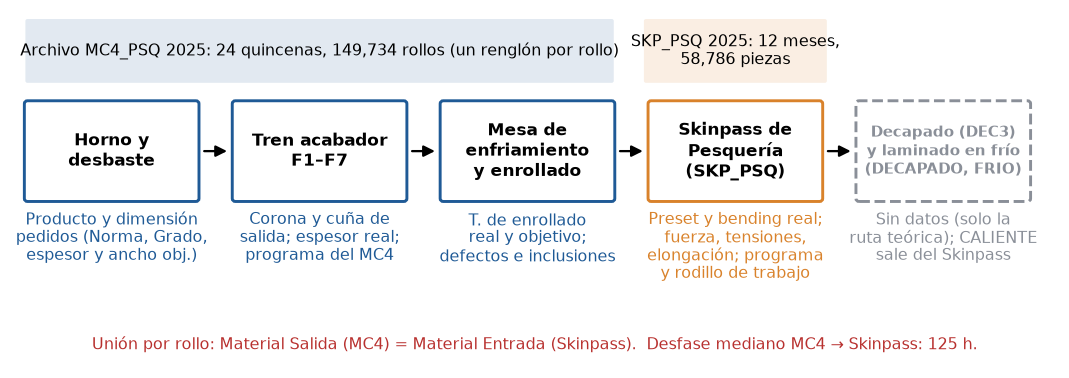

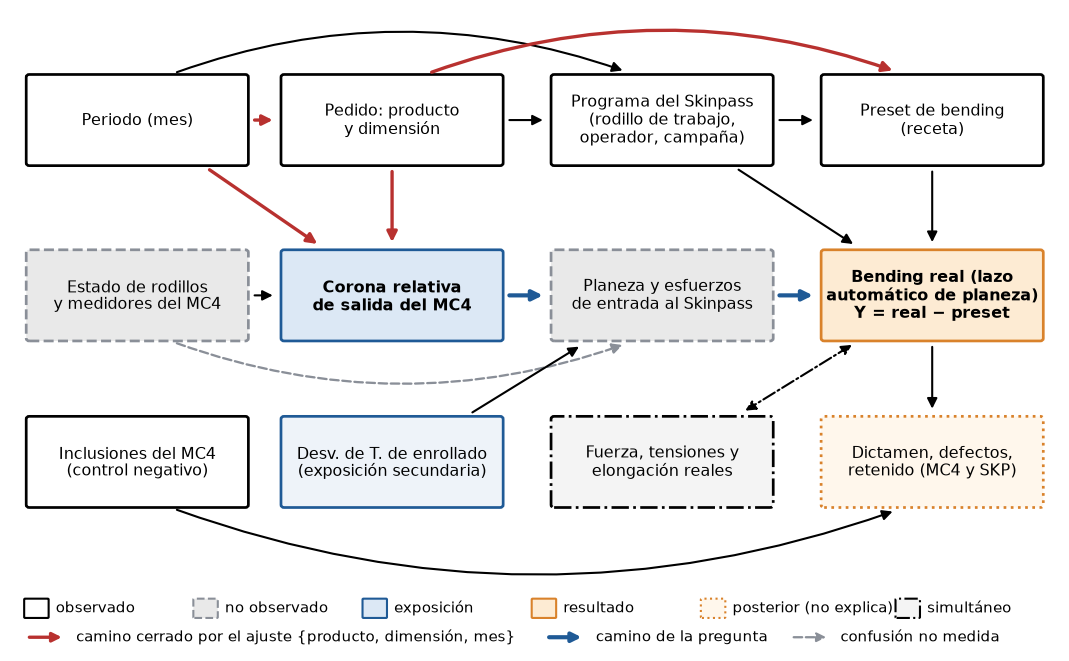

In [10]:
guardar_articulo(mapa_proceso_skp(n_mc4=len(m), n_skp=len(pz), desfase_h=float(des.median())), "mapa_proceso")
guardar_articulo(diagrama_causal_final(), "diagrama_causal")

## 10. Cifras para el texto del artículo (`outputs/tablas/cifras.json` → macros LaTeX)

In [11]:
from src.resultados import guardar_cifras, fmt
pp = pob.set_index("paso")["rollos"]
otras = cob_grupo.loc["Otras"]
guardar_cifras({
    "NRollosMC": fmt(pp["0"], 0), "NRollosRuta": fmt(pp["1"], 0), "NRollosSKP": fmt(pp["2"], 0),
    "NRollosCenso": fmt(pp["3"], 0), "NRollosAnalitica": fmt(pp["4"], 0), "NRollosAsoc": fmt(pp["5"], 0),
    "NExclCenso": fmt(pp["2"] - pp["3"], 0), "NExclSinY": fmt(pp["3"] - pp["4"], 0), "NExclSinCorona": fmt(pp["4"] - pp["5"], 0),
    "NRegistrosSKP": fmt(len(pz), 0), "NRegistrosSinLiga": fmt(int((~pz["liga_mc4"]).sum()), 0),
    "NRollosDivididos": fmt(int(rs["dividido"].sum()), 0), "PctDivididos": fmt(100 * rs["dividido"].mean(), 1),
    "CorrYPrimeraPieza": fmt(np.corrcoef(d["y_corr"], d["y_primera"])[0, 1], 2),
    "NOtras": fmt(otras["rollos"], 0), "PctOtrasEnSKP": fmt(otras["pct_en_skinpass"], 1),
    "PctCalienteEnSKP": fmt(cob_grupo.loc["M-P-CALIENTE-BOB-SKP", "pct_en_skinpass"], 1),
    "PctDecapadoEnSKP": fmt(cob_grupo.loc["M-P-DECAPADO-BOB-SKP", "pct_en_skinpass"], 1),
    "PctDicEnSKP": fmt(mens.loc["2025-12", "en_skinpass"], 1), "DesfaseMedianoH": fmt(des.median(), 0),
    "NProgramas": fmt(a["programa_skp"].nunique(), 0), "MedianaRollosPrograma": fmt(a.groupby("programa_skp").size().median(), 0),
    "NProductos": fmt(a["producto"].nunique(), 0), "NCeldas": fmt(a["celda"].nunique(), 0),
    "NRodillos": fmt(a["rodillo_trabajo"].nunique(), 0),
    "YMediana": fmt(a["y_corr"].median(), 0), "YMedia": fmt(a["y_corr"].mean(), 0), "YDE": fmt(a["y_corr"].std(), 0),
    "YPcinco": fmt(a["y_corr"].quantile(.05), 0), "YPnoventaycinco": fmt(a["y_corr"].quantile(.95), 0),
    "PctDefInspector": fmt(100 * a["def_inspector_skp"].mean(), 1), "PctRetenido": fmt(100 * a["retenido_skp"].mean(), 1),
    "PctRetenidoSinDef": fmt(100 * a.loc[sin_def, "retenido_skp"].mean(), 1),
    "PctModoElongacion": fmt(100 * a["modo_molino"].eq("Elongación").mean(), 1),
    "ElongMediana": fmt(el.median(), 2),
    "PctPresetCero": fmt(100 * a["preset_cero"].mean(), 1), "NPresetAlto": fmt(int(a["preset_alto"].sum()), 0),
    "PendRealPreset": fmt(b1, 2), "CorrRealPreset": fmt(r, 2),
    "PctPresetUnicoTodos": fmt(100 * (nu_todos == 1).mean(), 0), "PctPresetUnicoDos": fmt(100 * (uni == 1).mean(), 0),
    "PctProgUnRodillo": fmt(100 * (pr == 1).mean(), 1),
    "CoronaMedianaUm": fmt(a["corona_um"].median(), 0), "CoronaRelMediana": fmt(a["corona_rel_pct"].median(), 2),
    "EspesorMediano": fmt(a["Espesor"].median(), 2),
    "CoronaRelMedianaDic": fmt(exc.query("paso == '3' and grupo == 'excluidos'")["corona relativa mediana (%)"].iat[0], 2),
    "PctRetenidoSinCorona": fmt(exc.query("paso == '5' and grupo == 'excluidos'")["% RETENIDO en MC4"].iat[0], 1),
    "YMedianaSinCorona": fmt(exc.query("paso == '5' and grupo == 'excluidos'")["Y mediana (kN)"].iat[0], 0),
    "PctTensionEnrollado": fmt(100 * insp.iloc[0] / insp.sum(), 0),
    "NDimensiones": fmt(a["dimension"].nunique(), 0),
    "BendRealPresetCero": fmt(a.loc[c0, "bend_real"].median(), 0),
    "PctRealCeroPresetCero": fmt(100 * a.loc[c0, "bend_real"].eq(0).mean(), 1),
    "PresetPuno": fmt(q(a["bend_preset"], .01), 0), "PresetPnoventaynueve": fmt(q(a["bend_preset"], .99), 0),
    "RealPuno": fmt(q(a["bend_real"], .01), 0), "RealPnoventaynueve": fmt(q(a["bend_real"], .99), 0),
    "CoronaPcincoUm": fmt(q(a["corona_um"], .05), 0), "CoronaPnoventaycincoUm": fmt(q(a["corona_um"], .95), 0),
    "MedianaProgRodillo": fmt(rp.median(), 0),
    "PctYMayorCincuenta": fmt(100 * (a["y_corr"].abs() > 50).mean(), 0),
})

## 11. Tabla de población para Metodología (LaTeX)

In [12]:
from src import figuras_articulo as fa
tp = pob.copy()
tp["criterio"] = ["Rollos del MC4 en 2025", "Ruta teórica con SKP_PSQ (cualquier forma final)",
                  "Con registro en el Skinpass 2025", "Laminados antes del 1-dic-2025 (censura)",
                  "Con bending real y preset (Y definido)", "Además con corona relativa válida"]
fa.tabla_latex(tp, TABLAS_DIR / "tabla_poblacion.tex",
               {"paso": "Paso", "criterio": "Criterio", "rollos": "Rollos", "excluidos en el paso": "Excluidos",
                "programas del Skinpass": "Progr. SKP"},
               {"rollos": "{:,.0f}", "excluidos en el paso": "{:,.0f}", "programas del Skinpass": "{:,.0f}"},
               alineacion="cL{3.15cm}rrr")
print((TABLAS_DIR / "tabla_poblacion.tex").read_text())

\begin{tabular}{cL{3.15cm}rrr}
\toprule
Paso & Criterio & Rollos & Excluidos & Progr. SKP \\
\midrule
0 & Rollos del MC4 en 2025 & 149,734 & -- & -- \\
1 & Ruta teórica con SKP\_PSQ (cualquier forma final) & 50,016 & 99,718 & -- \\
2 & Con registro en el Skinpass 2025 & 47,410 & 2,606 & 858 \\
3 & Laminados antes del 1-dic-2025 (censura) & 44,313 & 3,097 & 831 \\
4 & Con bending real y preset (Y definido) & 44,272 & 41 & 831 \\
5 & Además con corona relativa válida & 43,208 & 1,064 & 831 \\
\bottomrule
\end{tabular}

